# ```OpenCV``` Tutorial #
### Instalation ###
```OpenCV```  can be installed via ```pip install opencv-python```.

### Documentation ###
- Learn ```OpenCV``` - [Link](https://learnopencv.com/getting-started-with-opencv/);
- ```OpenCV``` Documentation - [Link](https://opencv-tutorial.readthedocs.io/en/latest/);
- ```OpenCV``` Samples - [Link](https://github.com/opencv/opencv/tree/4.x/samples/data);
- Learn OpenCV (Getting Started) - [Link](https://learnopencv.com/getting-started-with-opencv/);

### Importing Dependencies ###

In [2]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

### What's a Pixel? ###
Images are made of ```pixels```. They are the colored dots that compose an image (if we zoom into an image we can see **squares of uniform color**). In ```OpenCV``` RGB is always presented as BGR.

### Colors ###
**Color Spaces**
The ```RGB``` colors space is a cube of dimension ```256 x 256 x 256```. The ```HSV``` color space is a cube of dimension ```180 x 256 x 256```.

**Main Colors**
- Black: ```(0, 0, 0)```;
- White: ```(255, 255, 255)```;
- Red: ```(0, 0, 255)```;
- Green: ```(0, 255, 0)```;
- Blue: ```(255, 0, 0)```;
- Cyan: ```(255, 255, 0)```;
- Magenta: ```(255, 0, 255)```;
- Yellow: ```(0, 255, 255)```;

### Images and Videos ###
**Read Image from File**

In [5]:
# Reading sample image
img = cv.imread(filename= cv.samples.findFile("./img/starry_night.jpg"), flags= cv.IMREAD_COLOR) # 'imread': loads image from file and returns OpenCV matrix (if can't read,returns empty matrix)
                                                                                                 #    'flags': format (IMREAD_COLOR: BGR 8-bit format- default, IMREAD_UNCHANGED: as is; IMREAD_GRAYSCALE: as intensity)
# Showing 'img'
cv.imshow(winname= "Starry Night", mat= img) # 'imshow': displays image in specified window
                                             #    'mat': image to be shown (matrix)
                                             #    'winname': window name of the window, 'img': image to be shown 
k = cv.waitKey(delay= 0) # 'waitKey': waits for a key event (ie key press) inifinitely 
                         #   'delay': delay in milliseconds (<=0: forever, >0: wait specified time)
                         # Displays window infinitely until any key is pressed (returns key that was pressed)

**Saving Image to File**

In [6]:
# Reading sample image (Same as above)
img = cv.imread(filename= cv.samples.findFile("./img/starry_night.jpg"), flags= cv.IMREAD_COLOR) # 'imread': loads image from file and returns OpenCV matrix (if can't read,returns empty matrix)
                                                                                                 #    'flags': format (IMREAD_COLOR: BGR 8-bit format- default, IMREAD_UNCHANGED: as is; IMREAD_GRAYSCALE: as intensity)
# Grayscaling 'img' 
img = cv.cvtColor(src= img, code= cv.COLOR_BGR2GRAY) # 'cvtColor': converts image from one color space to another (more below)
# Showing 'img'
cv.imwrite(filename= "./img/gray_starry_night.jpg", img= img) # 'imwrite': saves image to specified file (returns True if successful, False otherwise)
                                                              #    'filename': name of file to save (format based on extension)
                                                              #    'img': image to be saved (matrix)

True

**Capture Video from Camera**<br>
Let's capture a video from the camera (built-in laptop), convert it into grayscale and display it:

In [10]:
# Creating a 'VideoCapture' object to read from webcam
cap = cv.VideoCapture(index= 0) # 'VideoCapture': class for video capturing from video files, image sequences, cameras
                                 #   'index': device index (0: default camera)
# Checking whether webcam was initialized successfully
if not cap.isOpened(): # 'isOpened': True if video capturing is initialized
    print("Camera not initialized") # If error, open camera using 'cap.open()'
    exit()
else:
    print(f"Frame width x height: {cap.get(cv.CAP_PROP_FRAME_WIDTH)} x {cap.get(cv.CAP_PROP_FRAME_HEIGHT)}") # 'get': returns specified properties
# Looping...
while True:
    # Capturing frame-by-frame
    ret, frame = cap.read() # 'read()': reads, decode and returns next video frame
                            #    'ret': returning value (True if frame is read correctly), False otherwise
                            #    'frame': video frame itself (as matrix)
    # If frame is not read correctly (ret=True)
    if not ret:
        print("Can't receive frame (stream end?). Exiting...")
        break
    # Frame operations from here on
    gray = cv.cvtColor(src= frame, code= cv.COLOR_BGR2GRAY) # 'cvtColor': converts image from one color space to another
                                                            #   'src': input image (array) 
                                                            #   'code': output image (array; COLOR_BGR2GRAY: BGR/RGB to Grayscale)
    # Display the resulting frame
    cv.imshow(winname= "Webcam Capture", mat= gray) # Opens new window to display webcam capture in grayscale
    if cv.waitKey(1) == ord("q"): # Waits for 1ms for user to press a key, and if that key is 'q'...break loop
        break
# When done, release the capture
cap.release() # 'release()': closes video file/capturing device
cv.destroyAllWindows() # 'destroyAllWindows()': destroys all OpenCV created windows

Frame width x height: 640.0 x 480.0


**Playing Video from File**<br>
Playing video from file works the same as capturing it from camera, just change the index to a video file name:

In [9]:
# Creating a 'VideoCapture' object to read from video file
cap = cv.VideoCapture("./video/video_file_test.avi")
# Checking whether file was opened successfully (same as above)
if not cap.isOpened():
    print("Error: Could not open video file")
    exit()
else:  
    # Looping (while file is open)...   
    while cap.isOpened():
        # Capturing frame-by-frame (same as above)
        ret, frame = cap.read()
        # If frame is not read correctly (ret=True; same as above)
        if not ret:
            # Resets frame index tracker back to first frame (loops playback)
            cap.set(propId= cv.CAP_PROP_POS_FRAMES, value= 0) # 'CAP_PROP_POS_FRAMES': 0-based index of frame to be decoded/captured next
            continue # Skips rest of loop to read the first frame again
        # Frame operations from here on
        gray = cv.cvtColor(src= frame, code= cv.COLOR_BGR2GRAY) 
        # Display the resulting frame
        cv.imshow(winname= "Video File", mat= gray)
        if cv.waitKey(25) == ord("q"): # 'waitKey(25)': playback speed (25ms per frame)
                                       # Plays video and listens for user input ('q' key press)
            break
# When done, release the capture (same as above)
cap.release() 
cv.destroyAllWindows() 

**Saving Video to File**<br>
For images, we use ```cv.imwrite()```, for videos we need a ```cv.VideoWriter``` object and specify the ```FourCC``` code (4 bytes used to specify the ```codec```; available codes here [link](http://www.fourcc.org)):

In [11]:
# Reading from video file
cap = cv.VideoCapture("./video/video_file_test.avi")
# Setting the 'VideoWriter' object
fourcc = cv.VideoWriter_fourcc(*'XVID') # 'VideoWriter_fourcc': static method that constructs the fourcc code to be used in constructor (below)
                                        #    '*': unpacks the string into separate characters (ie. 'X', 'V', 'I', 'D')
                                        #    'XVID': Xvid MPEG-4 codec (best suited for legacy '.avi' formats) 
# Creating the 'VideoWriter' object (provides API for writing video files or image sequences)
out = cv.VideoWriter(filename= "./video/video_file_zoom_test.avi", # 'filename': output video file name (with extension)
                     fourcc= fourcc, # 'fourcc': 4-character code (codec)
                     fps= 20.0, # 'fps': frame rate (of output video stream)
                     frameSize= (640,  480)) # 'frameSize': frames size (of output video stream)
# Looping (while file is open)...  
while cap.isOpened():
    # Capturing frame-by-frame (same as above)
    ret, frame = cap.read()
    # If frame is not read correctly (ret=True, same as above)
    if not ret:
        print("Can't receive frame (stream end?). Exiting...")
        break
    # Flipping each frame vertically (upside down)
    frame = cv.flip(src= frame, flipCode= 0) # 'flip()': flips 2D array vertically, horizontally, or both
                                                #    'src': input image (array)
                                                #    'flipCode': flag to specify direction (0: vertical, >0: horizontal, <0: both)
    # Writting the flipped frame to file
    out.write(frame) # 'write()': writes frame to output file
    # Display the resulting frame
    cv.imshow(winname= "Zoom Video File", mat= frame)
    if cv.waitKey(25) == ord('q'): # Plays video and listens for user input ('q' key press)
        break
# When done, release the capture (same as above)
cap.release() # Original
out.release() # Ouput
cv.destroyAllWindows()

**Adding an Overlay**<br>
An overlay can be added to a window to add a line of text during a certain time (in case of a video). This requires ```Qt``` support by default (```cv.displayStatusBar()``` also requires it), which is not compiled by ```pip``` binaries.

In [12]:
## Bypassing 'cv.displayOverlay'
# Reading sample image 
img = cv.imread(filename= "./img/messi.jpg", flags= cv.IMREAD_COLOR)
# Copying image (avoid modifying original)
output = img.copy() # 'copy()': returns deep copy of array (instead of reference)
overlay = img.copy()
# Calculating text bounding box size 
# 'getTextSize': calculates width/height of text string
(text_width, text_height), baseline = cv.getTextSize(text= f"Width: {img.shape[1]}\nHeight: {img.shape[0]}\nChannels: {img.shape[2]}", # 'text': input text
                                                     fontFace= cv.FONT_HERSHEY_SIMPLEX, # 'fontFace': font type (more here https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html#ga0f9314ea6e35f99bb23f29567fc16e11)
                                                     fontScale= 1.0, # 'fontScale': font scale factor (multiplied by font-specific base size)
                                                     thickness= 2) # 'thickness': line thickness (px)
# Defining coordinates for background box
x, y = 0, 30
padding = 10 # Extra space around text
box_coords = ((x, y + baseline + padding), (img.shape[1], y - text_height - padding)) # 'box_coords': tuple of top-left and bottom-right coordinates
## Adding overlay rectangle + text to image ('output')
# Drawing solid black rectangle as background
cv.rectangle(img= overlay, pt1= box_coords[0], pt2= box_coords[1], color= (0, 0, 0) , thickness= cv.FILLED) # More below on "Drawing" section
# Blending overlay with original image using alpha
cv.addWeighted(src1= overlay, # 'src1': first input array (image)
               alpha= 0.5, # 'alpha': weight of the first array elements
               src2= output, # 'src2': second input array (image of same size and channel number as 'src1')
               beta= 1 - 0.5, # 'beta': weight of the second array elements
               gamma= 0, # 'gamma': scalar added to each sum
               dst= output) # 'dst': output array that has same size and number of channels as input arrays

# Drawing text over semi-transparent box
cv.putText(img= output, # 'img': image to be drawn on
           text= "Transparent Overlay", # 'text': string content
           org= (x + padding, y), # 'org': bottom-left corner of text (x,y)
           fontFace= cv.FONT_HERSHEY_SIMPLEX, # 'fontFace': font type 
           fontScale= 1.0, # 'fontScale': font scale factor
           color= (255, 255, 255), # 'color': white color (BGR tuple)
           thickness= 2, 
           lineType= cv.LINE_AA)
# Showing final output
cv.imshow(winname= "Overlay Text", mat= output)
# Closes window when any key is pressed
cv.waitKey(0)
cv.destroyAllWindows()

### Mouse Inputs ###
**Mouse Events**<br>
```setMouseCallback``` function attaches a mouse callback to the image window:

In [13]:
# Defining the callback 
def mouse_track(event, x, y, flags, param): # 'x','y','flags','param': all passed when callback is triggered
    global img, img_backup # Accessing global 'img' variable to modify it inside callback
    # Defining text to display
    text = f"[Mouse Coordinates] X: {x}, Y: {y}"
    # Checking the mouse event type
    if event == cv.EVENT_MOUSEMOVE: # Common Mouse Events: EVENT_LBUTTONDOWN: left mouse button pressed
                                    #                      EVENT_RBUTTONDOWN: right mouse button pressed
                                    #                      EVENT_MBUTTONDOWN: scroll wheel button pressed
                                    #                      EVENT_LBUTTONUP: left mouse button released
                                    #                      EVENT_MOUSEMOVE: mouse pointer is moving
                                    #                      EVENT_LBUTTONDBLCLK: left mouse button double-clicked
        # Reseting image to clear previous text
        img = img_backup.copy()
        # Drawing current coordinates
        cv.putText(img= img, # 'img': image to be drawn on
                   text= text, # 'text': string content
                   org= (x + 10, y - 10), # 'org': bottom-left corner of text (x,y)
                   fontFace= cv.FONT_HERSHEY_SIMPLEX, # 'fontFace': font type 
                   fontScale= 0.75, # 'fontScale': font scale factor
                   color= (255,255,255), # 'color': white color (BGR tuple)
                   thickness= 2,
                   lineType= cv.LINE_AA);
    else:
        pass

In [14]:
# Reading sample image 
img = cv.imread(filename= "./img/messi.jpg", flags= cv.IMREAD_COLOR)
# Keeping a clean backup to clear the screen
img_backup = img.copy()
# Displaying the image
cv.namedWindow("Interactive Mouse")
cv.setMouseCallback(window_name= "Interactive Mouse", on_mouse= mouse_track) # 'setMouseCallback': sets mouse handler for specified window
                                                                             #    'winname': name of window that will use the callback
                                                                             #    'onMouse': callback function called when mouse events occur
while True:
    cv.imshow(winname= "Interactive Mouse", mat= img)
    # Break loop with 'q'
    if cv.waitKey(1) == ord("q"): # Plays video and listens for user input ('q' key press)
        break
# Closes window when any key is pressed
cv.destroyAllWindows()

**Drawing with Mouse**<br>
We can use the mouse to change the pixel color at the mouse position (when the mouse button is pressed, the ```flag``` is set to 1):

In [15]:
def mouse_draw(event, x, y, flags, param):
    global img, img_backup # Accessing global 'img' variable to modify it inside callback
    # Defining text to display
    text = f"[Mouse Coordinates] X: {x}, Y: {y}"
    # Checking the mouse event type
    if flags == 1:
        img[y, x] = [0, 0, 255]
    else:
        cv.imshow(winname= "Interactive Mouse", mat= img_backup)

In [16]:
# Reading sample image 
img = cv.imread(filename= "./img/messi.jpg", flags= cv.IMREAD_COLOR)
# Keeping a clean backup to clear the screen
img_backup = img.copy()
# Displaying the image
cv.namedWindow("Interactive Mouse")
cv.setMouseCallback(window_name= "Interactive Mouse", on_mouse= mouse_draw) 
                                                                            
while True:
    cv.imshow(winname= "Interactive Mouse", mat= img)
    # Break loop with 'q'
    if cv.waitKey(1) == ord("q"): # Plays video and listens for user input ('q' key press)
        break
# Closes window when any key is pressed
cv.destroyAllWindows()

### Drawing Shapes ###
**Line**

In [17]:
# Creating a black image
img = np.zeros((512, 512, 3), dtype= np.uint8)
# Drawing a diagonal blue line with thickness of 5 px
cv.line(img= img, # 'line()': draws line segment connecting 2 points
        pt1= (0,0), # 'pt1': first point (x,y)
        pt2= (511,511), # 'pt2': second point (x,y)
        color= (255,0,0), # 'color': line color (BGR tuple)
        thickness= 5, # 'thickness': line thickness (px)
        lineType= cv.LINE_AA); # 'lineType': line type (LINE_AA: anti-aliased, looks better for non-integer coordinates)
                               #             Available: cv.FILLED, cv.LINE_4 (4-connected), cv.LINE_8 (8-connected), cv.LINE_AA (anti-aliased)

**Rectangle**

In [18]:
# Drawing a green rectangle at the top-right corner of image with thickness of 3 px
cv.rectangle(img= img, # 'rectangle()': draws rectangle specified by two opposite corners
             pt1= (384,0),
             pt2= (510,128),
             color= (0,255,0),
             thickness= 3,
             lineType= cv.LINE_4);

**Circle**

In [19]:
# Drawing a red circle inside the rectangle (above)
cv.circle(img= img, # 'circle()': draws a circle specified by center and radius
          center= (447,63),
          radius= 63,
          color= (0,0,255),
          thickness= -1,
          lineType= cv.LINE_8);

**Polylines**

In [20]:
## Drawing a white polygon (closed polylines) with 4 vertices and thickness of 4 px
# Creating vertices coordinates
pts = np.array([[10,5], [20,30], [70,20], [50,10]], dtype= np.int32) # No need to close the polygon ('isClosed' param below)
# Reshaping the vertices into  ROWSx1x2 array (required by 'polylines'; ROWS: number of vertices of type 'int32')
pts = pts.reshape((-1, 1, 2)) # '-1': infers number of rows from length of array (in this case: ROWSx1x2 = 4, thus ROWS=4)
# Drawing the polygon
cv.polylines(img= img,
             pts= [pts],
             isClosed= True, # 'isClosed': flag to whether draw closed polyline (if True, it repeats first vertice at end)
             color= (0,255,255),
             thickness= 4,
             lineType= cv.LINE_4);

**Polygon**

In [21]:
## Drawing a cyan polygon (filled) with 3 vertices and thickness of 2 px
# Creating vertices coordinates
pts = np.array([[50,50], [150,150], [150,50]], dtype= np.int32) # No need to close the polygon ('isClosed' param below)
# Drawing the polygon
cv.fillPoly(img= img,
            pts= [pts],
            color= (255,255,0),
            lineType= cv.LINE_4);

**Ellipse**

In [22]:
# Drawing a yellow ellipse centered at center of image, rotated 30 degrees, and with thickness of 2 px
cv.ellipse(img= img, # 'ellipse()': draws an ellipse specified by center, axes, and rotation
           center= (256,256), # 'center': center of ellipse (x,y)
           axes= (40,20), # 'axes': half of the size of ellipse's main axes
           angle= 30, # 'angle': ellipse rotation in degrees (positive values mean clockwise rotation)
           startAngle= 0, # 'startAngle': starting angle of the ellipse arc in degrees (measured from horizontal axis)
           endAngle= 360, # 'endAngle': ending angle of the ellipse arc in degrees (measured from horizontal axis)
           color= (0,0,255),
           thickness= 2,
           lineType= cv.LINE_8);

**Text**

In [23]:
# Drawing text
cv.putText(img= img,
           text= 'OpenCV Test', # 'text': string to be drawn
           org= (10,500), # 'org': bottom-left corner of text (x,y)
           fontFace= cv.FONT_HERSHEY_SIMPLEX, # 'fontFace': font type (more here https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html#ga0f9314ea6e35f99bb23f29567fc16e11)
           fontScale= 2.5, # 'fontScale': font scale factor (multiplied by font-specific base size)
           color= (255,255,255),
           thickness= 2,
           lineType= cv.LINE_AA);

In [24]:
# Display the image
cv.imshow(winname= "Drawings", mat= img)
cv.waitKey(0)
cv.destroyAllWindows()

### Basic Operations on Images ###
**Accessing and Modifying Pixels**

In [25]:
# Reading sample image 
img = cv.imread("./img/messi.jpg")
# Accessing a single pixel
px = img[100,100] # Pixel at row 100, column 100 
print(f"Pixel BGR Values: {px}") # Returns BGR values as array (or intensity value if grayscale image)
# Modifying a single pixel's value
img[100,100] = [255,255,255] # Sets pixel at row 100, column 100 to white 
print(f"Modified Pixel BGR Values: {img[100,100]}")

Pixel BGR Values: [ 61  89 149]
Modified Pixel BGR Values: [255 255 255]


**Accessing Image Properties**<br>
Properties include number of rows, columns, channels, type of image data, number of pixels, etc:

In [26]:
# Reading sample image (Same as above)
img = cv.imread("./img/messi.jpg")
# Accessing properties
print(f"Image Shape: {img.shape}") # 'shape': returns tuple of (rows, columns, channels)
                                   #          'channels' is returned only for color images (not grayscale)
print(f"Image Size: {img.size}") # 'size': returns total number of pixels (rows x columns x channels)
print(f"Image Data Type: {img.dtype}") # 'dtype': returns data type (ie. uint8, float32, etc - important for debugging)

Image Shape: (411, 624, 3)
Image Size: 769392
Image Data Type: uint8


**(Image Transformations) Translation**<br>
Translating an image is shifting it along the ```x```/```y``` axes. An *affine transformation* can be obtained via a *transformation matrix* ```M```.  (the first row of the matrix is ```[1, 0, x]```, the second is ```[0, 1, y]```).

In [31]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Creating the transformation matrix
M = np.float32([[1, 0, 50], [0, 1, 50]]) # Translating 50px to right and 50px down
# Applying transformation to image
# 'warpAffine': applies an affine transformation to an image 
shifted = cv.warpAffine(src= img, # 'src': input image (array)
                        M= M, # 'M': 2x3 transformation matrix
                        dsize= (int(img.shape[1]), int(img.shape[0]))) # 'dsize': output image size (width, height) (if 0, computed from src.size() and M)
# Display the image
cv.imshow(winname= "Img Transformation", mat= shifted)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Rotation**<br>
To rotate an image we need to specify the center of rotation and apply an *affine transformation*, via the ```cv.getRotationMatrix2D``` with 3 arguments: rotation center, rotation angle, and scale factor.

In [33]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Calculating the image center
center = (int(img.shape[1]) / 2, int(img.shape[0] / 2))
# Creating the transformation matrix
M = cv.getRotationMatrix2D(center= center, # 'center': rotation center
                           angle= 180, # 'angle': angle in degrees
                           scale= 1.0) # 'scale': isotropic scale factor (1 keeps original size)
# 'warpAffine': applies an affine transformation to an image 
rotated = cv.warpAffine(src= img, # 'src': input image (array)
                        M= M, # 'M': 2x3 transformation matrix
                        dsize= (int(img.shape[1]), int(img.shape[0]))) # 'dsize': output image size (width, height) (if 0, computed from src.size() and M)
# Display the image
cv.imshow(winname= "Img Transformation", mat= rotated)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Scale**<br>
Scales an image via an *affine transformation*, via, once again, the ```cv.getRotationMatrix2D```.

In [35]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Calculating the image center
center = (int(img.shape[1]) / 2, int(img.shape[0] / 2))
# Creating the transformation matrix
M = cv.getRotationMatrix2D(center= center, # 'center': rotation center
                           angle= 0, # 'angle': angle in degrees
                           scale= 1/2) # 'scale': isotropic scale factor (1 keeps original size)
# 'warpAffine': applies an affine transformation to an image 
rotated = cv.warpAffine(src= img, # 'src': input image (array)
                        M= M, # 'M': 2x3 transformation matrix
                        dsize= (int(img.shape[1]), int(img.shape[0]))) # 'dsize': output image size (width, height) (if 0, computed from src.size() and M)
# Display the image
cv.imshow(winname= "Img Scaling", mat= rotated)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Flipping**<br>
Flips the image horizontally or vertically based on ```flipCode```.

In [ ]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Flips image (flipCode: 0: vertically, 1: horizontally) 
flipped = cv.flip(img, 1) # Flips horizontally
# Display the image
cv.imshow(winname= "Img Flipping", mat= flipped)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Values Arithmetic**<br>
The functions ```add```/```subtract``` allow to add/subtract values to each pixel in an image (as a result the image becomes brighter/darker).

In [ ]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Creating the transformation matrix (we need it in 'add'/'subtract')
M = np.ones(img.shape, dtype= "uint8") * 40 # '* 40': makes all values 40
# Adding (40,40,40) to each pixel
brighter = cv.add(img, M)
# Display the image
cv.imshow(winname= "Img Values Ops", mat= brighter)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Bitwise Operations**<br>
Bitwise operations act on grayscale images (most often it is used on black/white images). We start wtih a circle and a square shape and calculate bitwise operations.

In [ ]:
# Setting the padding ('d')
d = 15
# Creating a square
rect = np.zeros((100, 100), np.uint8) # Creates a solid black 100x100 canvas
cv.rectangle(img= rect, # 'img': source image where rectangle will be drawn
             pt1= (d, d), # 'pt1': top-left vertex
             pt2= (100-d, 100-d), # 'pt2': bottom-right vertex
             color= 255, # 'color': specified as tuple (scalar works as grayscale values; 255: white, 0: black)
             thickness= -1) # 'thickness': thickness of lines that make up the rectangle (-1: solid rectangle)
# Creating the circle
circle = np.zeros((100, 100), np.uint8) # Creates a solid black 100x100 canvas
cv.circle(img= circle, 
          center= (50, 50), # 'center': center coordinates
          radius= 40, # 'radius': circle radius
          color= 255, 
          thickness= -1)
## Performing bitwise operations
# 'bitwise_and': acts as logical AND
bit_and = cv.bitwise_and(src1= rect, # 'src1': first input array
                         src2= circle) # 'src2': second input array
# 'bitwise_or': acts as logical OR
bit_or = cv.bitwise_or(src1= rect, src2= circle) 
# 'bitwise_xor': acts as logical XOR
bit_xor = cv.bitwise_xor(src1= rect, src2= circle) 
# 'np.hstack': stacks arrays sequentially in horizontal direction
bitwise_horz = np.hstack([rect, circle, bit_and, bit_or, bit_xor])
# Display the image
cv.imshow(winname= "Img Bitwise Ops", mat= bitwise_horz)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Masking**<br>
Masks are used to extract only a certain part of an image.

In [ ]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Creating the transformation matrix as background
mask = np.zeros(img.shape[:2], dtype= "uint8") # 'img.shape[:2]': mask MUST have same structural dimensions as image (in our case, 2)
# Creating the circle
cv.circle(img= mask, 
          center= (500, 100), # 'center': center coordinates
          radius= 100, # 'radius': circle radius
          color= 255, 
          thickness= -1)
# 'bitwise_and': acts as logical AND
masked = cv.bitwise_and(src1= img, # 'AND'-ing any pixel value with itself changes nothing, which allows the 'mask' to cut out the shape
                        src2= img, 
                        mask= mask) # 'mask': single-channel mask (acts as cookie cutter pressed over dough)
                                    #         where mask is black (0): ignores the image pixel and drops a black one (gate closed)
                                    #         where mask is white (255): outputs the exact original image pixel (gate open)
# 'np.hstack': stacks arrays sequentially in horizontal direction
masked_stack = np.hstack([img, masked])
# Display the image
cv.imshow(winname= "Img Masking", mat= masked_stack)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Split Channels**<br>
We split an RGB image into it’s components via ```split()```.

In [ ]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Resizing the 'img'
img = cv.resize(src= img, 
                dsize= None, # When used ignores 'fx'/'fy'
                fx= 0.5, # 'fx': scale factor along horizontal axis (width)
                fy= 0.5, # 'fy': scale factor along • vertical axis (height)
                interpolation= cv.INTER_CUBIC) # 'interpolation': specifies how pixel values are calculated when shrinking/stretching image
                                               # 'cv.INTER_CUBIC': bicubic interpolation
                                               #    Available: 'INTER_NEAREST': nearest neighbor interpolation
                                               #               'INTER_LINEAR': bilinear interpolation
                                               #               'INTER_AREA': resampling using pixel area relation (preferred for image decimation)
                                               #               'INTER_LANCZOS4': Lanczos interpolation over 8x8 neighborhood
                                               #               'INTER_LINEAR_EXACT': bit exact bilinear interpolation
                                               #               'INTER_MAX': mask for interpolation codes
                                               #               'WARP_FILL_OUTLIERS': flags all of the destination image pixels
# Splitting 'img' channels
b_1chn, g_1chn, r_1chn = cv.split(img) # 'split': returns single channels images
# Converting 1D channels back to 3D
b_3ch = cv.cvtColor(src= b_1chn, code= cv.COLOR_GRAY2BGR) # 'cvtColor': converts an image from one color space to another
                                                          #    'src': input image array
                                                          #    'code': color space conversion code ('COLOR_GRAY2BGR': 1 -> 3 channels by duplicating single grayscale layer 3 times)
g_3ch = cv.cvtColor(g_1chn, cv.COLOR_GRAY2BGR)
r_3ch = cv.cvtColor(r_1chn, cv.COLOR_GRAY2BGR)
# 'np.hstack': stacks arrays sequentially in horizontal direction
channels = np.hstack([img, b_3ch, g_3ch, r_3ch])
# Display the image
cv.imshow(winname= "Img Split Channels", mat= channels)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Merge Channels**<br>
We merge RGB channels via ```merge()```.

In [ ]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Resizing the 'img'
img = cv.resize(src= img, 
                dsize= None, 
                fx= 0.5, 
                fy= 0.5, 
                interpolation= cv.INTER_CUBIC) 
# Creating a matrix to zero RGB values (depending on the channel)
z = np.zeros(img.shape[:2], dtype= "uint8") # 'img.shape[:2]': mask MUST have same structural dimensions as image (in our case, 2)
# Splitting 'img' channels
b_1chn, g_1chn, r_1chn = cv.split(img) # 'split': returns single channels images
# Merging (by zeroing all values that dont belong to the channel)
blue = cv.merge([b_1chn, z, z])
green = cv.merge([z, g_1chn, z])
red = cv.merge([z, z, r_1chn])
# 'np.hstack': stacks arrays sequentially in horizontal direction
merged_channels = np.hstack([img, blue, green, red])
# Display the image
cv.imshow(winname= "Img Merge Channels", mat= merged_channels)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Color Spaces**<br>
Above we've seen the RGB color space, however there're other spaces such as ```Hue-Saturation-Value``` and ```L*a*b``` (Lightness, Red-Green axis, Blue-Yellow axis).

In [60]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Resizing the 'img'
img = cv.resize(src= img, 
                dsize= None, 
                fx= 0.5, 
                fy= 0.5, 
                interpolation= cv.INTER_CUBIC) 
# Converting 'img' from RGB to other color spaces
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV) # 'COLOR_BGR2HSV': splits color into Hue (color type), Saturation (vibrancy), and Value (brightness)
lab = cv.cvtColor(img, cv.COLOR_BGR2LAB) # 'COLOR_BGR2LAB': converts image from default 'BGR' color space to 'CIE L*a*b*' color space
# 'np.hstack': stacks arrays sequentially in horizontal direction
color_spaces = np.hstack([img, hsv, lab])
# Display the image
cv.imshow(winname= "Img Color Spaces", mat= color_spaces)
cv.waitKey(0)
cv.destroyAllWindows()

**(Image Transformations) Affine Transformation**<br>
Creating an interactive app that lets the user rotate/scale an image in real time by clicking and dragging the mouse.

In [22]:
# Mouse events callback function
# Callback function automatically receives 5 arguments from 'setMouseCallback()'
#   'event': integer code representing the specific mouse interaction
#       -- Standard Mouse Events 
#       EVENT_MOUSEMOVE: mouse cursor moved over the window
#       EVENT_LBUTTONDOWN: right mouse button was pressed
#       EVENT_MBUTTONDOWN: middle mouse button was pressed
#       EVENT_LBUTTONUP: left mouse button was released
#       EVENT_RBUTTONUP: right mouse button was released
#       EVENT_MBUTTONUP: middle mouse button was released
#       -- Double-Click Events 
#       EVENT_LBUTTONDBLCLK: left mouse button was double-clicked
#       EVENT_RBUTTONDBLCLK: right mouse button was double-clicked
#       EVENT_MBUTTONDBLCLK: middle mouse button was double-clicked
#       -- Scroll Wheel Events
#       EVENT_MOUSEWHEEL: vertical mouse wheel was scrolled (forward or backward)
#       EVENT_MOUSEHWHEEL: horizontal mouse wheel was scrolled
#   'x': x-coordinate of the mouse cursor relative to the window/image
#   'y': y-coordinate of the mouse cursor relative to the window/image
#   'flags': bitwise flags indicating whether specific modifier keys or mouse buttons were pressed during the event
#   'userdata': optional custom object/variable passed as third argument in 'setMouseCallback()'

def mouse_events(event, x, y, flags, param): 
    # Declaring global variables
    global img, p0, p1
    # Checks for event type
    if event == cv.EVENT_LBUTTONDOWN: # Triggers when clicks left button: updates both
        p0 = (x, y)
        p1 = (x, y)
    elif event == cv.EVENT_MOUSEMOVE and flags == cv.EVENT_FLAG_LBUTTON: # Triggers while moving mouse with left button pressed ('flags'): updates p1 to current position
        p1 = (x, y)
    elif event == cv.EVENT_LBUTTONUP: # Triggers when releases left button: updates p1 to final position
        p1 = (x, y)
    
    # Skips tracking if user hasn't clicked yet
    if p0 is None or p1 is None:
        return
    # Declaring local variables
    height, width = img.shape[:2]
    RED_COLOR = (0, 0, 255)
    # Measureing distance between click (p0) and drag (p1)    
    dx = p1[0] - p0[0]
    dy = p1[1] - p0[1]
    # Calculating angle (via tangent)
    angle = -np.degrees(np.arctan2(dy, dx)) # 'np.degrees()': converts radians to degrees
    # Calculating the hypotenuse (and dividing by 50; acts as standard 1.0x scaling) 
    dist = np.sqrt(dx**2 + dy**2) / 50
    # Creating a 2D affine transformation matrix
    # 'getRotationMatrix2D()': calculates a 2×3 affine transformation matrix used for rotating/scaling a 2D image around a 'center'
    M = cv.getRotationMatrix2D(center= p0, # First click as center
                               angle= angle, 
                               scale= dist)
    # Distorting the original 'img' using 'M'
    # 'warpAffine()': applies an affine transformation to an image
    img_warp = cv.warpAffine(src= img, # 'src': input image
                             M= M, # 'M': 2 × 3 transformation matrix
                             dsize= (width, height)) # 'dsize': size of output image
    # Creating a superimposing a solid red tracking line (from initial click, p0, to cursor position, p1)
    cv.line(img_warp, p0, p1, RED_COLOR, 2)
    cv.imshow(winname= "Affine Transform", mat= img_warp)

In [ ]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Creating variables
p0, p1 = None, None
# Display the image
cv.imshow(winname= "Affine Transform", mat= img)
# 'setMouseCallback': binds a mouse action handler to a specific GUI window (arguments passed as positional arguments)
cv.setMouseCallback("Affine Transform", # 'winname': window where mouse events are tracked (MUST match 'imshow()')
                    mouse_events, # callback function to be called every time a mouse event occurs in window 
                    None) # user-defined data passed to callback function ('params' is None, since 'p0'/'p1' are global)                                        
cv.waitKey(0)
cv.destroyAllWindows()

### Histograms ###
**Grayscale Histogram**<br>
```calcHist()``` calculates the histogram (frequency distribution of pixel intensities) for one or more images.

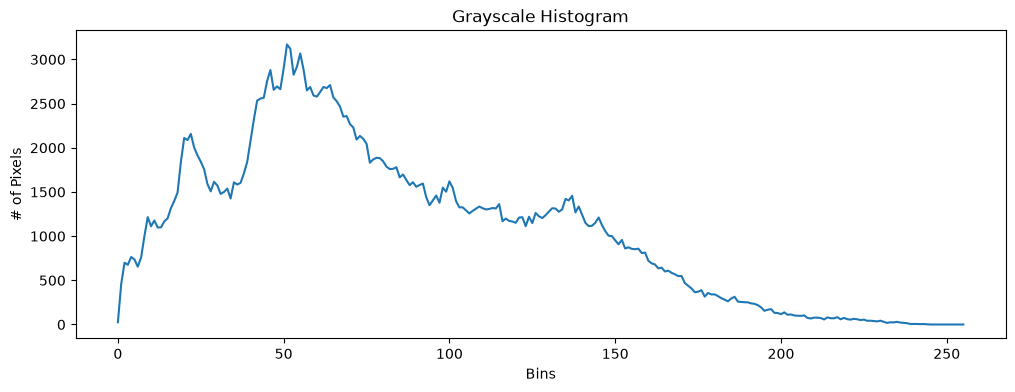

In [5]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Grayscaling 'img' 
gray = cv.cvtColor(src= img, code= cv.COLOR_BGR2GRAY) # 'cvtColor': converts image from one color space to another
                                                      #   'src': input image (array) 
                                                      #   'code': output image (array; COLOR_BGR2GRAY: BGR/RGB to Grayscale)
# Calculating the histogram
# 'calcHist': calculates the histogram (frequency distribution of pixel intensities)
hist = cv.calcHist(images= [gray], # 'images': list of source images
                   channels= [0], # 'channels': list of channel indices ([0]: grayscale, [0]: (for BGR) blue, [1]: (for BGR) green, [2]: (for BGR) red)
                   mask= None, # 'mask': (optional) mask image of same size as 'images'
                   histSize= [256], # 'histSize': list with number of bins for each channel (8-bit intensity resolution: [256])
                   ranges= [0, 256]) # 'ranges': list with boundaries of intensity values to measure (8-bit images: [0, 256])
# Plotting with matplotlib
plt.figure(figsize= (12, 4))
plt.title("Grayscale Histogram")
plt.xlabel("Bins")
plt.ylabel("# of Pixels")
plt.plot(hist)
plt.show()              

cv.waitKey(0)
cv.destroyAllWindows()

**Color Histogram**<br>

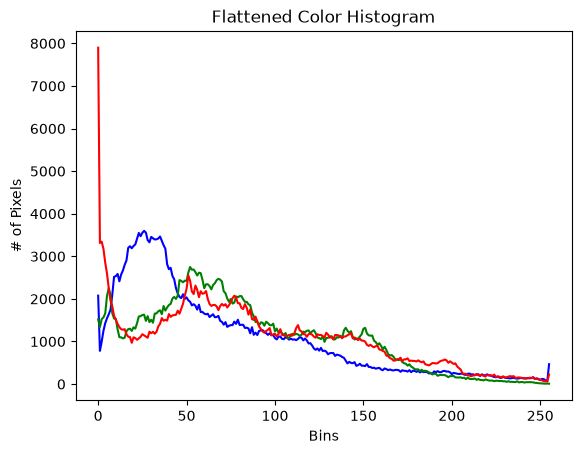

In [ ]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Splitting 'img' channels
bgr_1chn = cv.split(img) # 'split': returns single channels images
                         #          'bgr_1chn' is a tuple for b, g, r (1 channel)
colors = "b", "g", "r"

# Plotting with matplotlib
plt.figure()
plt.title("Flattened Color Histogram")
plt.xlabel("Bins")
plt.ylabel("# of Pixels")
# Looping channels...
for (channel, color) in zip(bgr_1chn, colors):
    hist = cv.calcHist(images= [channel], # 'calcHist': calculates the histogram (frequency distribution of pixel intensities)
                       channels= [0], 
                       mask= None, 
                       histSize= [256], 
                       ranges= [0, 256]) 
    plt.plot(hist, color= color)
plt.show()              

cv.waitKey(0)
cv.destroyAllWindows()

**Blurring**<br>
```cv.blur()``` function smooths an image by setting each pixel to the average value of its surrounding neighbors.

In [ ]:
# Reading sample image 
img = cv.imread("./img/fish.jpg")
# Creating a NumPy array (ndarray) representing the blurred image
blurred = cv.blur(img, 
                  ksize= (5, 5)) # 'ksize': kernel size; (width, height) to consider in window (must be positive; odd numbers recommended: 3x3, 5x5, 7x7)
                                 # Available: 'GaussianBlur', 'medianBlur', 'bilateralFilter'
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, blurred])
# Display the image
cv.imshow(winname= "Blur", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

### Filters and Convolution ###
**Simple Thresholding**<br>
For every pixel, the same threshold is applied. If the pixel is smaller then the threshold, it is set to 0, otherwise it's set to the maximum.

In [10]:
# 'fromfunction': executes a specified function over every coordinate combination defined by target shape
img = np.fromfunction(function= lambda i, j: j, # 'function': callable object; each parameter is an array representing coordinates
                      shape= (50, 256), # 'shape': shape of the output array
                      dtype= "uint8") # 'dtype': data type of coordinate arrays passed to function
# Display the image
cv.imshow(winname= "Thresholding", mat= img)
cv.waitKey(0)
cv.destroyAllWindows()

**Binary Thresholding**<br>
Converts a grayscale image into a binary image (consisting only of two pixel values, typically black and white) by comparing each pixel against a fixed threshold value (if value is higher than threshold, it's assigned a maximum value; otherwise, zero).

In [ ]:
# Reading sample image 
img = cv.imread("./img/eye.png")
# Binary thresholding 'img'
# 'threshold()': perform global image thresholding (segment image by separating foreground objects from background based on pixel intensity)
#                returns 'ret' (threshold representing final cutoff threshold value), 'dst' (destination image)
ret, img_bin_thresh = cv.threshold(src= img, # 'src': source image
                                   thresh= 100, # 'thresh': reference value to test each pixel against
                                   maxval= 255, # 'maxval': value assigned if threshold condition is met
                                   type= cv.THRESH_BINARY) # 'type': flag that defines the logic applied to pixels
                                                           # Available: 'THRESH_BINARY' (if pixel > thresh, set to maxval; else 0)
                                                           #            'THRESH_BINARY_INV' (if pixel > thresh, set to 0; else maxval)
                                                           #            'THRESH_TRUNC' (if pixel > thresh, set to thresh; else keep original) 
                                                           #            'THRESH_TOZERO' (if pixel > thresh, keep original; else 0)
                                                           #            'THRESH_TOZERO_INV' (if pixel > thresh, set to 0; else, keep original)
ret, img_bin_inv_thresh = cv.threshold(src= img, thresh= 100, maxval= 255, type= cv.THRESH_BINARY_INV)
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_bin_thresh, img_bin_inv_thresh])
# Display the image
cv.imshow(winname= "Binary Thresholding", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

**To Zero**<br>

In [27]:
# Reading sample image 
img = cv.imread("./img/eye.png")
# Binary thresholding 'img'
ret, img_bin_thresh = cv.threshold(src= img, thresh= 100, maxval= 255, type= cv.THRESH_TOZERO) 
ret, img_bin_inv_thresh = cv.threshold(src= img, thresh= 100, maxval= 255, type= cv.THRESH_TOZERO_INV)
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_bin_thresh, img_bin_inv_thresh])
# Display the image
cv.imshow(winname= "Binary Thresholding to Zero", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

**2D Convolution**<br>
2D convolution slides a small matrix (called a ```kernel``` or filter) across an image to transform its pixels (primarily used for tasks like blurring, sharpening, detecting edges, and extracting structural features).

In [ ]:
# Reading sample image 
img = cv.imread("./img/eye.png")
# Creating the kernel
kernel = np.ones((5, 5), "float32") / (5**2)
# Convoluting the 'img'
img_conv = cv.filter2D(src= img, # 'src': input source image
                       ddepth= -1, # 'ddeepth': desired depth of destination image (-1: output image has same depthas input)
                       kernel= kernel) # 'kernel': convolution matrix (must be single-channel floating-point array)
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_conv])
# Display the image
cv.imshow(winname= "2D Convolution", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

### Morphological Transformations ###
**Erosion**<br>
```cv.erode()``` shrinks the foreground (bright pixels) of an image by computing a local minimum over a sliding window (kernel). A pixel in the original image is kept 1 (bright) only if all pixels under the kernel are 1; otherwise, it is eroded to 0.

In [31]:
# Reading sample image 
img = cv.imread("./img/j.png")
# Creating the kernel
x = 2 # 'x': value
odd_n = 2*x + 1 # Creating an odd number (required for morphological operations)
kernel = np.ones((odd_n, odd_n), np.uint8)
# Applying erosion (shrinks white (foreground) regions in a binary/grayscale image)
img_erosion = cv.erode(src= img, # 'src': input image
                       kernel= kernel, # 'kernel': defines the neighborhood shape
                       iterations= 1) # 'iterations': how many times to repeatedly apply the erosion
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_erosion])
# Display the image
cv.imshow(winname= "Erosion", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

**Dilation**<br>
```cv.dilate()``` expands the boundaries of foreground objects (typically white regions) in an image. It computes a local maximum over the area defined by a sliding window called a kernel (counterpart to ```cv.erode()```).

In [32]:
# Reading sample image 
img = cv.imread("./img/j.png")
# Creating the kernel
x = 2 # 'x': value
odd_n = 2*x + 1 # Creating an odd number (required for morphological operations)
kernel = np.ones((odd_n, odd_n), np.uint8)
# Applying erosion (shrinks white (foreground) regions in a binary/grayscale image)
img_erosion = cv.dilate(src= img, # 'src': input image
                        kernel= kernel, # 'kernel': defines the neighborhood shape
                        iterations= 1) # 'iterations': how many times to repeatedly apply the erosion
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_erosion])
# Display the image
cv.imshow(winname= "Erosion", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

**Opening**<br>
```cv.morphologyEx()``` is an all-in-one method used to perform advanced morphological transformations. This function uses an operation flag (```op````) to execute Opening/Closing.

In [34]:
# Reading sample image 
img = cv.imread("./img/j.png")
# Creating the kernel
x = 3 # 'x': value
odd_n = 2*x + 1 # Creating an odd number (required for morphological operations)
kernel = np.ones((odd_n, odd_n), np.uint8)
# Applying erosion (shrinks white (foreground) regions in a binary/grayscale image)
img_open = cv.morphologyEx(src= img, # 'src': input image
                           op= cv.MORPH_OPEN, # 'op': operation type flag (specifies the transformation)
                           kernel= kernel) # 'kernel': defines the neighborhood shape
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_open])
# Display the image
cv.imshow(winname= "Erosion", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

In [35]:
# Reading sample image 
img = cv.imread("./img/j.png")
# Creating the kernel
x = 3 # 'x': value
odd_n = 2*x + 1 # Creating an odd number (required for morphological operations)
kernel = np.ones((odd_n, odd_n), np.uint8)
# Applying erosion (shrinks white (foreground) regions in a binary/grayscale image)
img_open = cv.morphologyEx(src= img, # 'src': input image
                           op= cv.MORPH_CLOSE, # 'op': operation type flag (specifies the transformation)
                           kernel= kernel) # 'kernel': defines the neighborhood shape
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_open])
# Display the image
cv.imshow(winname= "Erosion", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

**Image Gradient (Laplacian)**<br>
Calculates the ```Laplacian``` of an image (second-order derivative operator used primarily for edge detection and measuring image blur/sharpness). It calculates the sum of second-order spatial derivatives along the X and Y axes.

In [36]:
# Reading sample image 
img = cv.imread("./img/sudoku.jpg")
# Grayscaling 'img' 
gray = cv.cvtColor(src= img, code= cv.COLOR_BGR2GRAY) # 'cvtColor': converts image from one color space to another
# Applying laplacian
img_laplace = cv.Laplacian(src= img, # 'src': input image
                           ddepth= 8) # 'ddepth': depth/data type of the output image
                                      #           since we calculate a second derivative, pixel variations can result in negative values (if input image is standard unsigned will result in losing edges)
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_laplace])
# Display the image
cv.imshow(winname= "Erosion", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

**Canny Edge Detection**<br>
Implements Canny Edge Detection algorithm (considered gold standard for edge detection because of its multi-stage approach; yields clean, thin, and continuous lines).

In [39]:
# Reading sample image 
img = cv.imread("./img/sudoku.jpg")
# Grayscaling 'img' 
gray = cv.cvtColor(src= img, code= cv.COLOR_BGR2GRAY) # 'cvtColor': converts image from one color space to another
# Applying Canny Edge algorithm (returns binary, 2 channels, edge map)
img_canny = cv.Canny(image= img, # 'src': input image
                     threshold1= 100, # 'threshold1': first threshold for hysteresis (typically lower threshold)
                     threshold2= 200) # 'threshold2': second threshold for hysteresis (typically higher threshold)
# Convert 2D Canny image into 3D/3-channel image (still black and white)
img_canny_3ch = cv.cvtColor(img_canny, cv.COLOR_GRAY2BGR)
# 'np.hstack': stacks arrays sequentially in horizontal direction
stacked = np.hstack([img, img_canny_3ch])
# Display the image
cv.imshow(winname= "Erosion", mat= stacked)
cv.waitKey(0)
cv.destroyAllWindows()

### Application Features ###
An app is the place where *keyboard* and *mouse* input is detected. Despite, being able to open 1+ windows, only one is the ```active``` window at any time. To make a window ```active```, user has to click with the mouse in it. Each window has several objects, which are organized as hierarchical ```nodes```. Each window can have one ```active node```. The keyboard ```events``` are sent from the application to the ```active window```, and from it to the ```active node```.

If there is no ```active node```, then the window can use the keyboard input as *shortcuts*. If neither an ```active node```, nor the ```active window``` handles the ```event```, it falls back to the app, which can handle it.

**```App``` Class**<br>
Creates a named window (```namedWindow()```) and a method to run the application:

In [ ]:
class App:
    def __init__(self, image_path= "./img/moon_topography.jpg"): # Initialize the application state and resources
        # Window params
        self.window_name = "OpenCV App"
        # Load base image
        self.img = cv.imread(image_path)
        if self.img is None:
            raise FileNotFoundError(f"Could not load image from: {image_path}")
        # Setup the user interface
        self.setup_ui()

    # Methods
    def setup_ui(self): # Create the window and attach callbacks
        # 'namedWindow': creates a placeholder window that can host images or handle events
        cv.namedWindow(winname= self.window_name, 
                       flags= cv.WINDOW_NORMAL | cv.WINDOW_KEEPRATIO) # Register a resizable window with aspect ratio locking

    def process_image(self, low_threshold= 50, high_threshold= 150): # Apply filters and algorithms based on the current state
        # Convert to grayscale and apply Canny using state variables
        gray = cv.cvtColor(src= self.img, code= cv.COLOR_BGR2GRAY)
        edges = cv.Canny(image= gray, threshold1= low_threshold, threshold2= high_threshold)
        # Convert edges back to 3 channels to match the original image layout
        edges_3ch = cv.cvtColor(src= edges,  code= cv.COLOR_GRAY2BGR)
        # Stack horizontally side-by-side
        return np.hstack([self.img, edges_3ch])

    def render(self): # Process the frame and update the active window
        display_frame = self.process_image() # 'process_image()': defined above
        cv.imshow(winname= self.window_name, mat= display_frame)

    def run(self): # Main application lifecycle loop
        # Trigger the initial render so image shows immediately on launch
        self.render()
        print("Application running. Press any key in the GUI window to exit...")
        cv.waitKey(0) # '0': means to wait without a time limit
        cv.destroyAllWindows()

In [46]:
# Instantiating the app
app = App()
app.run()

Application running. Press any key in the GUI window to exit...


**```App``` Class with Multiple Windows**<br>
To track all windows and specify the currently active window, we add class variables:

In [7]:
class App:
    # Class variables
    windows = []
    curr_win = None
    
    def __init__(self, image_path= "./img/moon_topography.jpg", curr_win= None): 
        # Windows
        self.window_img = "Original"
        self.window_edges = "Canny Edges"
        # Load base image
        self.img = cv.imread(image_path)
        if self.img is None:
            raise FileNotFoundError(f"Could not load image from: {image_path}")
        # Setup the user interface
        self.setup_ui()

    # Methods
    def setup_ui(self, width= 800, height= 800): # Create separate placeholder windows
        # Window 1: original image
        cv.namedWindow(winname= self.window_img, 
                       flags= cv.WINDOW_KEEPRATIO) 
        # Force dimensions
        cv.resizeWindow(winname= self.window_img, 
                        width= width, 
                        height= height)
        # Window 2: original image
        cv.namedWindow(winname= self.window_edges, 
                       flags= cv.WINDOW_KEEPRATIO) 
        # Force dimensions
        cv.resizeWindow(winname= self.window_edges, 
                        width= width, 
                        height= height)

    def process_image(self, low_threshold= 50, high_threshold= 150): # Apply filters and algorithms based on the current state
        # Convert to grayscale and apply Canny using state variables
        gray = cv.cvtColor(src= self.img, code= cv.COLOR_BGR2GRAY)
        edges = cv.Canny(image= gray, threshold1= low_threshold, threshold2= high_threshold)
        # Convert edges back to 3 channels to match the original image layout
        edges_3ch = cv.cvtColor(src= edges,  code= cv.COLOR_GRAY2BGR)
        # Return both images as tuple
        return self.img, edges_3ch

    def render(self): # Process the frame and update both windows
        # Unpack the separate images 
        orig_frame, edge_frame = self.process_image() 
        # Push each image to its respective window
        cv.imshow(winname= self.window_img, mat= orig_frame)
        cv.imshow(winname= self.window_edges, mat= edge_frame)

    def run(self): # Main application lifecycle loop
        # Trigger the initial render so image shows immediately on launch
        self.render()
        print("Application running. Press any key in the GUI window to exit...")
        cv.waitKey(0) # '0': means to wait without a time limit
        cv.destroyAllWindows()

In [8]:
# Instantiating the app
app = App()
app.run()

Application running. Press any key in the GUI window to exit...


### Face Detection ###
**Face Detection (Image)**<br>
Keep in mind: ```cv.CascadeClassifier``` models do not recognize inclined, tilted (must be frontal) (past 10 to 15 degrees) or rotated faces.

In [ ]:
# Defining color
RED = (0, 0, 255)
# Loading sample image 
img = cv.imread("./img/nasa_faces.jpg")
img_faces = cv.imread("./img/nasa_faces.jpg")
# Grayscaling 'img' (needed for face detection algo)
gray = cv.cvtColor(src= img, code= cv.COLOR_BGR2GRAY) # 'cvtColor': converts image from one color space to another
# Loading the model
path = cv.data.haarcascades + 'haarcascade_frontalface_default.xml' # 'path': path to pre-trained XML file with model for recognizing faces
                                                                    #         comes pre-installed with OpenCV
face_detector = cv.CascadeClassifier(path) # 'CascadeClasssifier': loads trained model into OpenCV's cascade classifier
# Scanning image for faces (returns list of bounding boxes where faces are found)
face_rects = face_detector.detectMultiScale(image= gray, # 'image': source image
                                            scaleFactor= 1.1, # 'scaleFactor': tells algorithm how much the image size is reduced at each image scale (1.1 means reduce by 10% to catch faces of different sizes)
                                            minNeighbors= 5, # 'minNeighbors': specifies how many neighbors each candidate rectangle should have to retain it (higher values mean fewer detections but higher quality)
                                            minSize= (30, 30), # 'minSize': discards any detected faces smaller than 30x30 pixels
                                            flags= cv.CASCADE_SCALE_IMAGE)
print(f"Found {len(face_rects)} face(s)")
# Looping rectangles...
for rect in face_rects:
    # Unpacking 'rect'
    x, y, w, h = rect
    # Drawing the rectangle on 'img_faces'
    cv.rectangle(img= img_faces, 
                 pt1= (x, y), 
                 pt2= (x + w, y + h), 
                 color= RED, 
                 thickness= 2)
# 'np.vstack': stacks arrays sequentially in vertical direction
stacked = np.vstack([img, img_faces])
# Resizing stacked
# 'resize()': resizes an image to a specified size or downscales/upscales it using percentages
stacked_resize = cv.resize(src= stacked, 
                           dsize= None, # 'dsize': MUST be None if using 'fx'/'fy'
                           fx= 0.5, # 'fx': horizontal scale factor
                           fy= 0.5, # 'fy': vertical scale factor
                           interpolation= cv.INTER_AREA) # 'interpolation': algorithm used to recalculate pixel values
# Display the image
cv.imshow(winname= "Image Faces", mat= stacked_resize)
cv.waitKey(0)
cv.destroyAllWindows()

Found 25 face(s)


**Face Detection (Video)**<br>

In [9]:
# Defining color
RED = (0, 0, 255)
# Loading the model
path = cv.data.haarcascades + 'haarcascade_frontalface_default.xml' # See above
face_detector = cv.CascadeClassifier(path) # 'CascadeClasssifier': loads trained model into OpenCV's cascade classifier

# Defining the detect function
def detect(gray_frame): # Detects faces in 'gray' image
    global frame, gray 
    face_rects = face_detector.detectMultiScale(image= gray, # 'image': source image
                                                scaleFactor= 1.1, 
                                                minNeighbors= 5, 
                                                minSize= (30, 30), 
                                                flags= cv.CASCADE_SCALE_IMAGE)
    # Looping rectangles...
    for rect in face_rects:
        # Unpacking 'rect'
        x, y, w, h = rect
        # Drawing the rectangle on 'gray'
        cv.rectangle(img= frame, 
                     pt1= (x, y), 
                     pt2= (x + w, y + h), 
                     color= RED, 
                     thickness= 2)
    return frame

# Defining the webcam object
cap = cv.VideoCapture(0) # 'VideoCapture': opens default built-in webcam (0: default primary webcam)

# Looping...
while True:
    # Capture frame-by-frame
    ret_bool, frame = cap.read() # 'read': captures, decodes, and returns the next video frame from a video file
                               #    'ret_bool': boolean value indicating success (True: frame was grabbed and decoded correctly)
    # Grayscaling 'img' (needed for face detection algo)
    gray = cv.cvtColor(src= frame, code= cv.COLOR_BGR2GRAY) # 'cvtColor': converts image from one color space to another
    # Detecting faces in 'frame'
    frame_faces = detect(gray)
    # Display the image
    cv.imshow(winname= "Video Faces", mat= frame_faces)
    # Exit check
    if cv.waitKey(1) == ord("q"): # Waits for 1ms for user to press a key, and if that key is 'q'...break loop
        break
    
cv.destroyAllWindows()

### Object Detection ###
```YOLO``` (You Only Look Once) is an extremely fast multi object detection algorithm which uses Convolutional Neural Network (CNN) to detect and identify objects. The neural network is basically a sequence of connected convolutional layers (```conv```), rectifier linear units (```relu```) and other elements. 

In order to run the network we need to download the pre-trained [YOLO weight file](https://pjreddie.com/media/files/yolov3.weights)  (237 MB) and [configuration file](https://opencv-tutorial.readthedocs.io/en/latest/_downloads/10e685aad953495a95c17bfecd1649e5/yolov3.cfg) (```.cfg```).

**Create a Blob**<br>

In [18]:
# Loading sample image 
img = cv.imread("./img/horse.jpg")
cv.imshow(winname= "Original", mat= img)
cv.waitKey(0)
cv.destroyAllWindows()

In [19]:
# Creating the YOLO model (input configuration and weight files to model and load the NN)
nn = cv.dnn.readNetFromDarknet("./yolo/yolov3.cfg", "./yolo/yolov3.weights")
nn.setPreferableBackend(cv.dnn.DNN_BACKEND_OPENCV)

In [ ]:
# Determine the output layers (YOLO NN has 254 components)
ln = nn.getLayerNames()
print(len(ln), ln)

254 ('conv_0', 'bn_0', 'leaky_1', 'conv_1', 'bn_1', 'leaky_2', 'conv_2', 'bn_2', 'leaky_3', 'conv_3', 'bn_3', 'leaky_4', 'shortcut_4', 'conv_5', 'bn_5', 'leaky_6', 'conv_6', 'bn_6', 'leaky_7', 'conv_7', 'bn_7', 'leaky_8', 'shortcut_8', 'conv_9', 'bn_9', 'leaky_10', 'conv_10', 'bn_10', 'leaky_11', 'shortcut_11', 'conv_12', 'bn_12', 'leaky_13', 'conv_13', 'bn_13', 'leaky_14', 'conv_14', 'bn_14', 'leaky_15', 'shortcut_15', 'conv_16', 'bn_16', 'leaky_17', 'conv_17', 'bn_17', 'leaky_18', 'shortcut_18', 'conv_19', 'bn_19', 'leaky_20', 'conv_20', 'bn_20', 'leaky_21', 'shortcut_21', 'conv_22', 'bn_22', 'leaky_23', 'conv_23', 'bn_23', 'leaky_24', 'shortcut_24', 'conv_25', 'bn_25', 'leaky_26', 'conv_26', 'bn_26', 'leaky_27', 'shortcut_27', 'conv_28', 'bn_28', 'leaky_29', 'conv_29', 'bn_29', 'leaky_30', 'shortcut_30', 'conv_31', 'bn_31', 'leaky_32', 'conv_32', 'bn_32', 'leaky_33', 'shortcut_33', 'conv_34', 'bn_34', 'leaky_35', 'conv_35', 'bn_35', 'leaky_36', 'shortcut_36', 'conv_37', 'bn_37', 'le

In [ ]:
# Creating the 'blob' (input to the NN)
# 'blob' is a 4D numpy array object (images, channels, width, height)
# 'cv.dnn.blobFromImage()': preprocesses an input image and converts it into a 4-dimensional tensor (blob) that can be passed directly into NN model
#                           returns '(batch_size, channels, height, width)'
#                              'batch_size': number of images in the batch (1 if passing single image)
#                              'channels': number of chennles (typically 3: RGB/BGR)
#                              'height': specified by 'size' param
#                              'width': specified by 'size' param
blob = cv.dnn.blobFromImage(image= img, # 'image': input image (typically BGR format)
                            scalefactor= 1/255.0, # 'scalefactor': multiplies the pixel values after mean subtraction for normalization (ie. use 1/255 to scale pixels to [0, 1])
                            size= (416, 416), # 'size': (width, height) expected by NN model (can't be None)
                                              #         YOLO is trained to accept square inputs (multiples of 32)                
                            swapRB= True, # 'swapRB': True: NN expects RGB inputs (OpenCV's default is BGR format)
                            crop= True) # 'crop': controls image resizing behavior is handled (False: image is resized directly to 'size' without original aspect ratio; True: aspect ratio is preserved)
# Extract single channel from multi-dimensional 'blob'
red_ch = blob[0, 0, :, :] # NumPy allows comma-separated tuple 
                        #    '0': select first (and only image in the batch)
                        #    '0': select first channel (Red, since 'swapRB= True') 
                        #    ':': select all (416) rows of pixels
                        #    ':': select all (416) columns of pixels

In [ ]:
# Display the image 
cv.imshow(winname= "Red Channel Blob", mat= red_ch)
cv.waitKey(0)
cv.destroyAllWindows()

In [ ]:
# Inputing the blob in the NN
nn.setInput(blob) # 'setInput': preprocessed 4D array (must have a depth of 32-bit floating-point OR 8-bit unsigned integer)
# Calculating NN response
outputs = nn.forward(ln) # 'forward': runs forward propagation (inference) through NN layers (extracts layers' predictions)
                         #            returns NumPy array containing outputs of specific layer 
                         # 'outputs' object: are vectors of lenght 85
                         #    4: bounding box (centerx, centery, width, height)
                         #    1: box confidence
                         #    80: classes confidence (the ones mapped in './yolo/coco.names')

**Object Detection**<br>
As seen above, when using ```crop= True```, ```OpenCV``` clips the edges of the image to fit it into a *square*. This becomes a problem when drawing the rectangles, because ```w```/```h``` still measure the uncropped original image (bounding box coordinates get shifted and misaligned).
To prevent this shifting/distorting, we use ```Letterboxing```: we pad your original image with black bars to make it a perfect square before turning it into a ```blob```, allowing ```crop=False``` safely.

Additionally, we need to download the 80 object [classes names](https://opencv-tutorial.readthedocs.io/en/latest/_downloads/a9fb13cbea0745f3d11da9017d1b8467/coco.names) file (```.names```).

In [4]:
def letterbox_image(img, target_size= (416, 416)):
    # Defining the original/target dimensions
    img_h, img_w = img.shape[:2]
    trgt_w, trgt_h = target_size
    # Calculate the scale factor (while keeping aspect ratio)
    scale = min(trgt_w / img_w, trgt_h / img_h)
    new_w = int(img_w * scale)
    new_h = int(img_h * scale)
    # Resize the image to fit inside the target dimensions
    resized = cv.resize(src= img, # 'src': input image
                        dsize= (new_w, new_h), # 'dsize': target size of output image
                        interpolation= cv.INTER_CUBIC) # 'interpolation': how pixel values are calculated when shrinking/stretching image
    # Create a solid black background canvas
    # 'np.full()': creates a new array of a specified shape and type, filled completely with a value
    canvas = np.full(shape= (trgt_h, trgt_w, 3), # 'shape': new array shape
                     fill_value= 128, # 'fill_value': scalar to fill the new array (128 is neutral gray)
                     dtype= np.uint8) # dtype: array data type
    # Paste the resized image into the center of canvas
    dx = (trgt_w - new_w) // 2 # 'dx': x padding 
    dy = (trgt_h - new_h) // 2 # 'dy': y padding
    canvas[dy:dy + new_h, dx:dx + new_w] = resized # Defines a specific region in 'canvas' to be replaced (its pixels) by 'img'
    
    return canvas, scale, dx, dy

In [ ]:
# Loading sample image 
img = cv.imread("./img/dinner_table.jpg")
h, w = img.shape[:2] # 'shape': is a tuple (height, width, channel)
                              #          getting first 2
# Loading 80 objects classes names (and assigning random colors)
classes = open("./yolo/coco.names").read().strip().split("\n") # Classes names are divided by line breaks
np.random.seed(42) # Setting the seed for 'random'
colors = np.random.randint(0, 255, # Low/High values
                           size= (len(classes), 3), # 'size': output array shape (80x3)
                           dtype= "uint8") # 'dtype': desired data type

# Letterboxing 'img' (centering it and padding where needed)
padded_img, scale, dx, dy = letterbox_image(img, target_size= (416, 416))

# Loading the YOLO model (input configuration and weight files to model and load the NN)
nn = cv.dnn.readNetFromDarknet("./yolo/yolov3.cfg", "./yolo/yolov3.weights")
nn.setPreferableBackend(cv.dnn.DNN_BACKEND_OPENCV)

# Determine the output layers (YOLO NN has 254 components)
ln = nn.getLayerNames()
ln = [ln[i - 1] for i in nn.getUnconnectedOutLayers()] # 'getUnconnectedOutLayers': scans entire Neural Network graph and finds the "unconnected" layers (ie. output layer that produces predictions)
                                                          #                            returns flat list of integers

# Creating the 'blob' from image (input to the NN)
blob = cv.dnn.blobFromImage(image= padded_img, 
                            scalefactor= 1/255.0, 
                            size= (416, 416),               
                            swapRB= True, 
                            crop= True) 
red_ch = blob[0, 0, :, :] 
                    
# Inputing the blob in the NN
nn.setInput(blob) 
outputs = nn.forward(ln) # 'outputs': vectors of lenght 85 (bounding box, confidence, classes)

# Define placeholders for object detection features (boxes, confidence values, classes)
boxes = []
confidences = []
class_ids = []

# Looping 'outputs'...
for output in outputs: # 'output': vector of lenght 85
    for detection in output:
        scores = detection[5:] # Grabs all 80 class scores
        class_id = np.argmax(scores) # Finds the highest score index (corresponding class)
        confidence = scores[class_id] # Gets that specific score 
        # If 'detection' is reliable (50%+), it's kept...
        if confidence > 0.5:
            # Converting normalized coords to real píxels
            box = detection[:4] * np.array([416, 416, 416, 416]) # 'detection[:4]': extracts first 4 'detection' vector elements ('[center_x, center_y, box_width, box_height]')
                                                                 # '* np.array([w, h, w, h])': translates the 'detection' params to the original image (in our case, to the padded image; thus 416)
            (center_x, center_y, width, height) = box.astype("int") # Pixels must be integer numbers, thus rounding
            # Shifting from center to top-left corner (YOLO outputs coords based on center; OpenCVs draws with coords based on top-left) on padded canvas
            pad_x = int(center_x - (width / 2))
            pad_y = int(center_y - (height / 2))
            # Reversing the letterbox 
            x = int((pad_x - dx) / scale) # Subtract paddings
            y = int((pad_y - dy) / scale) 
            real_w = int(width / scale) # Expand back to original scale
            real_h = int(height / scale)
            # Rebuilding the box (top-left based)
            box = [x, y, int(real_w), int(real_h)]
            # Storing
            boxes.append(box)
            confidences.append(float(confidence))
            class_ids.append(class_id)

# Deduping overlapping boxes 
# 'cv.dnn.NMSBoxes': looks at all the boxes, checks how much they overlap and keeps only the ones with highest confidence score
indices = cv.dnn.NMSBoxes(bboxes= boxes, # 'bboxes': bounding boxes iterable
                          scores= confidences, # 'scores': confidence scores iterable
                          score_threshold= 0.5, # 'score_threshold': minimum confidence score required to keep a box
                          nms_threshold= 0.4) # 'nms_threshold': Intersection over Union (IoU) threshold (boxes with IoU greater than threshold will be supress if they have lower scores)

# If there are detections still...
if len(indices) > 0:
    # Flattening 'NMSBoxes' nested 2D array to 1D array
    for i in indices.flatten():
        # Grabbing top-left based params
        (x, y) = (boxes[i][0], boxes[i][1]) # Top-left box coords
        (box_w, box_h) = (boxes[i][2], boxes[i][3]) # Box dimensions
        color = [int(c) for c in colors[class_ids[i]]] # Corresponding class' color
        # Drawing the rectangle
        cv.rectangle(img= img, # 'img': source image matrix
                     pt1= (x, y), # 'pt1': top-left rectangle vertex
                     pt2= (x + box_w, y + box_h), # 'pt2': bottom-right rectangle vertex
                     color= color, # 'color': outline color
                     thickness= 2) # 'thickness': edge thickness
        # Writting the class and confidence
        text_str = "{}: {:.4f}".format(classes[class_ids[i]], confidences[i])
        cv.putText(img= img, # 'img': source image matrix to draw on
                   text= text_str, # 'text': string to be drawn
                   org= (x, y - 5), # 'org': bottom-left corner coords of text
                   fontFace= cv.FONT_HERSHEY_SIMPLEX, # 'fontFace': font type
                   fontScale= 0.5, # 'fontScale': scale factor (multiplied by font base size)
                   color= color, # 'color': font color
                   thickness= 1) # 'thickness': font lines' thickness

# Display the image 
cv.imshow(winname= "Object Detection", mat= img)
cv.waitKey(0)
cv.destroyAllWindows()

**Object Detection (Video)**<br>
Using ```letterbox_image``` from above:

In [11]:
# Loading the YOLO model (input configuration and weight files to model and load the NN)
nn = cv.dnn.readNetFromDarknet("./yolo/yolov3.cfg", "./yolo/yolov3.weights")
nn.setPreferableBackend(cv.dnn.DNN_BACKEND_OPENCV)

# Loading 80 objects classes names (and assigning random colors)
classes = open("./yolo/coco.names").read().strip().split("\n") # Classes names are divided by line breaks
np.random.seed(42) # Setting the seed for 'random'
colors = np.random.randint(0, 255, # Low/High values
                           size= (len(classes), 3), # 'size': output array shape (80x3)
                           dtype= "uint8") # 'dtype': desired data type

# Determine the output layers (YOLO NN has 254 components)
ln = nn.getLayerNames()
ln = [ln[i - 1] for i in nn.getUnconnectedOutLayers()] # 'getUnconnectedOutLayers': scans entire Neural Network graph and finds the "unconnected" layers (ie. output layer that produces predictions)
                                                       #                            returns flat list of integers

# Defining the webcam object
cap = cv.VideoCapture(0) # 'VideoCapture': opens default built-in webcam (0: default primary webcam)

# Looping...
while True:
    # Capture frame-by-frame
    ret_bool, frame = cap.read() # 'read': captures, decodes, and returns the next video frame from a video file
                               #    'ret_bool': boolean value indicating success (True: frame was grabbed and decoded correctly)
    # Getting frame dimensions
    h, w = frame.shape[:2] # 'shape': is a tuple (height, width, channel)
                         #          getting first 2
    # Letterboxing 'img' (centering it and padding where needed)
    padded_frame, scale, dx, dy = letterbox_image(frame, target_size= (416, 416))

    
    # Creating the 'blob' from image (input to the NN)
    blob = cv.dnn.blobFromImage(image= padded_frame, 
                                scalefactor= 1/255.0, 
                                size= (416, 416),               
                                swapRB= True, 
                                crop= True) 
  
    # Inputing the blob in the NN
    nn.setInput(blob) 
    outputs = nn.forward(ln) # 'outputs': vectors of lenght 85 (bounding box, confidence, classes)

    # Define placeholders for object detection features (boxes, confidence values, classes)
    boxes = []
    confidences = []
    class_ids = []

    # Looping 'outputs'...
    for output in outputs: # 'output': vector of lenght 85
        for detection in output:
            scores = detection[5:] # Grabs all 80 class scores
            class_id = np.argmax(scores) # Finds the highest score index (corresponding class)
            confidence = scores[class_id] # Gets that specific score 
            # If 'detection' is reliable (50%+), it's kept...
            if confidence > 0.5:
                # Converting normalized coords to real píxels
                box = detection[:4] * np.array([416, 416, 416, 416]) # 'detection[:4]': extracts first 4 'detection' vector elements ('[center_x, center_y, box_width, box_height]')
                                                                    # '* np.array([w, h, w, h])': translates the 'detection' params to the original image (in our case, to the padded image; thus 416)
                (center_x, center_y, width, height) = box.astype("int") # Pixels must be integer numbers, thus rounding
                # Shifting from center to top-left corner (YOLO outputs coords based on center; OpenCVs draws with coords based on top-left) on padded canvas
                pad_x = int(center_x - (width / 2))
                pad_y = int(center_y - (height / 2))
                # Reversing the letterbox 
                x = int((pad_x - dx) / scale) # Subtract paddings
                y = int((pad_y - dy) / scale) 
                real_w = int(width / scale) # Expand back to original scale
                real_h = int(height / scale)
                # Rebuilding the box (top-left based)
                box = [x, y, int(real_w), int(real_h)]
                # Storing
                boxes.append(box)
                confidences.append(float(confidence))
                class_ids.append(class_id)

    # Deduping overlapping boxes 
    # 'cv.dnn.NMSBoxes': looks at all the boxes, checks how much they overlap and keeps only the ones with highest confidence score
    indices = cv.dnn.NMSBoxes(bboxes= boxes, # 'bboxes': bounding boxes iterable
                            scores= confidences, # 'scores': confidence scores iterable
                            score_threshold= 0.5, # 'score_threshold': minimum confidence score required to keep a box
                            nms_threshold= 0.4) # 'nms_threshold': Intersection over Union (IoU) threshold (boxes with IoU greater than threshold will be supress if they have lower scores)

    # If there are detections still...
    if len(indices) > 0:
        # Flattening 'NMSBoxes' nested 2D array to 1D array
        for i in indices.flatten():
            # Grabbing top-left based params
            (x, y) = (boxes[i][0], boxes[i][1]) # Top-left box coords
            (box_w, box_h) = (boxes[i][2], boxes[i][3]) # Box dimensions
            color = [int(c) for c in colors[class_ids[i]]] # Corresponding class' color
            # Drawing the rectangle
            cv.rectangle(img= frame, # 'img': source image matrix
                        pt1= (x, y), # 'pt1': top-left rectangle vertex
                        pt2= (x + box_w, y + box_h), # 'pt2': bottom-right rectangle vertex
                        color= color, # 'color': outline color
                        thickness= 2) # 'thickness': edge thickness
            # Writting the class and confidence
            text_str = "{}: {:.4f}".format(classes[class_ids[i]], confidences[i])
            cv.putText(img= frame, # 'img': source image matrix to draw on
                    text= text_str, # 'text': string to be drawn
                    org= (x, y - 5), # 'org': bottom-left corner coords of text
                    fontFace= cv.FONT_HERSHEY_SIMPLEX, # 'fontFace': font type
                    fontScale= 0.5, # 'fontScale': scale factor (multiplied by font base size)
                    color= color, # 'color': font color
                    thickness= 1) # 'thickness': font lines' thickness
    # Display the image
    cv.imshow(winname= "Video Objects", mat= frame)
    # Exit check
    if cv.waitKey(1) == ord("q"): # Waits for 1ms for user to press a key, and if that key is 'q'...break loop
        break
    
cv.destroyAllWindows()

---